In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


In [2]:
df = pd.read_csv('train.csv')

print("Shape:", df.shape)
df[['GrLivArea', 'BedroomAbvGr', 'FullBath', 'HalfBath', 'SalePrice']].head()

Shape: (1460, 81)


,GrLivArea,BedroomAbvGr,FullBath,HalfBath,SalePrice
0,1710,3,2,1,208500
1,1262,3,2,0,181500
2,1786,3,2,1,223500
3,1717,3,1,0,140000
4,2198,4,2,1,250000


In [3]:
features = ['GrLivArea', 'BedroomAbvGr', 'FullBath', 'HalfBath',
            'BsmtFullBath', 'BsmtHalfBath']
target = 'SalePrice'

print("Missing values:", df[features + [target]].isnull().sum().sum())
df[features + [target]].describe().round(0)

Missing values: 0


,GrLivArea,BedroomAbvGr,FullBath,HalfBath,BsmtFullBath,BsmtHalfBath,SalePrice
count,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0
mean,1515.0,3.0,2.0,0.0,0.0,0.0,180921.0
std,525.0,1.0,1.0,1.0,1.0,0.0,79443.0
min,334.0,0.0,0.0,0.0,0.0,0.0,34900.0
25%,1130.0,2.0,1.0,0.0,0.0,0.0,129975.0
50%,1464.0,3.0,2.0,0.0,0.0,0.0,163000.0
75%,1777.0,3.0,2.0,1.0,1.0,0.0,214000.0
max,5642.0,8.0,3.0,2.0,3.0,2.0,755000.0


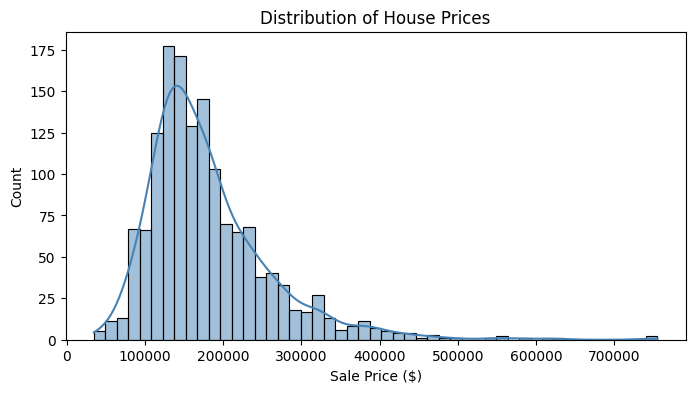

In [4]:
plt.figure(figsize=(8, 4))
sns.histplot(df[target], kde=True, color='steelblue')
plt.title('Distribution of House Prices')
plt.xlabel('Sale Price ($)')
plt.show()

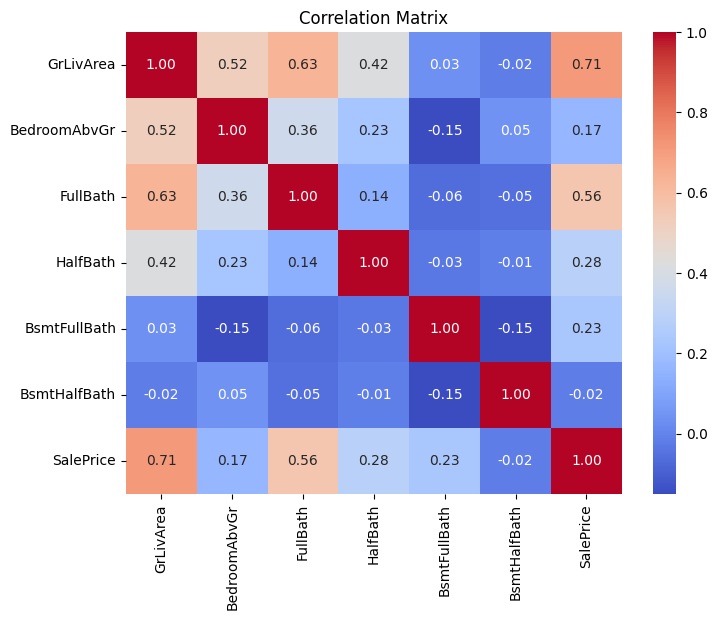

In [5]:
corr = df[features + [target]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

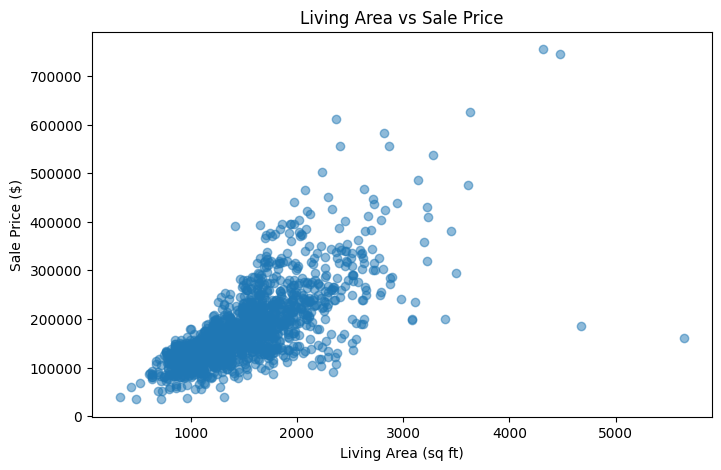

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df['GrLivArea'], df[target], alpha=0.5)
plt.xlabel('Living Area (sq ft)')
plt.ylabel('Sale Price ($)')
plt.title('Living Area vs Sale Price')
plt.show()

In [7]:
df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath'] +
                   df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])

df[['FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'TotalBath']].head()

,FullBath,HalfBath,BsmtFullBath,BsmtHalfBath,TotalBath
0,2,1,1,0,3.5
1,2,0,0,1,2.5
2,2,1,1,0,3.5
3,1,0,1,0,2.0
4,2,1,1,0,3.5


In [8]:
print("Before:", df.shape)

outliers = df[(df['GrLivArea'] > 4500) & (df['SalePrice'] < 300000)]
print("Outliers found:")
print(outliers[['GrLivArea', 'SalePrice']])

df = df.drop(outliers.index)
print("After:", df.shape)

Before: (1460, 82)
Outliers found:
      GrLivArea  SalePrice
523        4676     184750
1298       5642     160000
After: (1458, 82)


In [9]:
X = df[['GrLivArea', 'BedroomAbvGr', 'TotalBath']]
y = df['SalePrice']

print("X shape:", X.shape)
print(df[['GrLivArea', 'BedroomAbvGr', 'TotalBath', 'SalePrice']].corr()['SalePrice'].round(2))

X shape: (1458, 3)
GrLivArea       0.73
BedroomAbvGr    0.17
TotalBath       0.64
SalePrice       1.00
Name: SalePrice, dtype: float64


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (1166, 3)
Test:  (292, 3)


In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 2))
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_.round(2)
})
coef_df

Intercept: 26342.06


,Feature,Coefficient
0,GrLivArea,120.97
1,BedroomAbvGr,-30038.83
2,TotalBath,26254.97


In [12]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

def evaluate(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:6} | RMSE: ${rmse:,.0f} | MAE: ${mae:,.0f} | R²: {r2:.3f}")

evaluate(y_train, y_train_pred, "Train")
evaluate(y_test, y_test_pred, "Test")

Train  | RMSE: $46,207 | MAE: $33,295 | R²: 0.672
Test   | RMSE: $46,935 | MAE: $35,312 | R²: 0.601


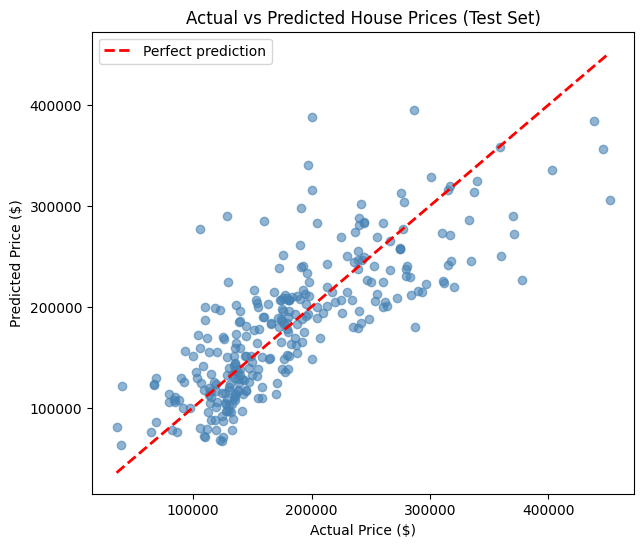

In [13]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.6, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', linewidth=2, label='Perfect prediction')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted House Prices (Test Set)')
plt.legend()
plt.show()

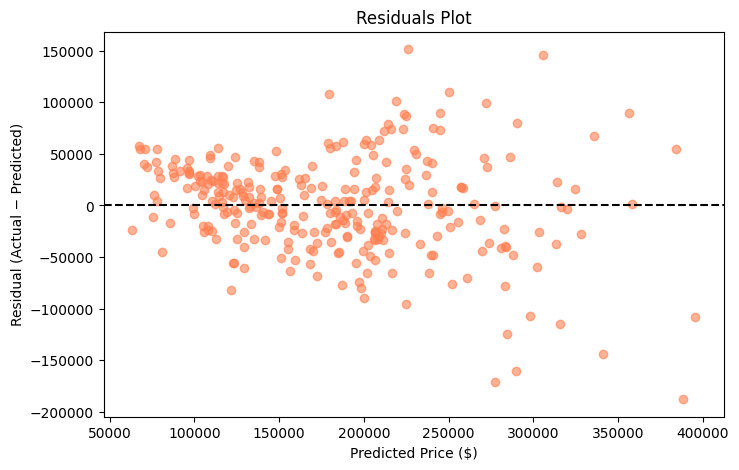

In [14]:
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred, residuals, alpha=0.6, color='coral')
plt.axhline(y=0, color='black', linestyle='--')
plt.xlabel('Predicted Price ($)')
plt.ylabel('Residual (Actual − Predicted)')
plt.title('Residuals Plot')
plt.show()

In [15]:
def predict_price(area, bedrooms, bathrooms):
    house = pd.DataFrame([[area, bedrooms, bathrooms]],
                         columns=['GrLivArea', 'BedroomAbvGr', 'TotalBath'])
    return model.predict(house)[0]

price = predict_price(2000, 3, 2.5)
print(f"House: 2000 sq ft, 3 bedrooms, 2.5 bathrooms")
print(f"Predicted price: ${price:,.0f}")

House: 2000 sq ft, 3 bedrooms, 2.5 bathrooms
Predicted price: $243,796


In [16]:
print("🏠 House Price Predictor")
print("-" * 30)

try:
    area = float(input("Living area (sq ft): "))
    bedrooms = int(input("Number of bedrooms: "))
    bathrooms = float(input("Number of bathrooms (e.g. 2.5): "))

    if area <= 0 or bedrooms < 0 or bathrooms < 0:
        print("❌ Please enter positive values.")
    else:
        price = predict_price(area, bedrooms, bathrooms)
        print(f"\n💰 Estimated price: ${price:,.0f}")
except ValueError:
    print("❌ Please enter numbers only.")

🏠 House Price Predictor
------------------------------
Living area (sq ft): 1000
Number of bedrooms: 2
Number of bathrooms (e.g. 2.5): 1

💰 Estimated price: $113,486


In [17]:
uploaded = files.upload()
test_df = pd.read_csv('test.csv')
print("Test shape:", test_df.shape)

Saving test.csv to test.csv
Test shape: (1459, 80)


In [18]:
print("Missing:")
print(test_df[['GrLivArea', 'BedroomAbvGr', 'FullBath', 'HalfBath',
               'BsmtFullBath', 'BsmtHalfBath']].isnull().sum())

test_df['BsmtFullBath'] = test_df['BsmtFullBath'].fillna(0)
test_df['BsmtHalfBath'] = test_df['BsmtHalfBath'].fillna(0)

test_df['TotalBath'] = (test_df['FullBath'] + 0.5 * test_df['HalfBath'] +
                        test_df['BsmtFullBath'] + 0.5 * test_df['BsmtHalfBath'])

Missing:
GrLivArea       0
BedroomAbvGr    0
FullBath        0
HalfBath        0
BsmtFullBath    2
BsmtHalfBath    2
dtype: int64


In [19]:
final_model = LinearRegression()
final_model.fit(X, y)

LinearRegression()

In [20]:
X_kaggle = test_df[['GrLivArea', 'BedroomAbvGr', 'TotalBath']]
predictions = final_model.predict(X_kaggle)

print(f"Min: ${predictions.min():,.0f} | Max: ${predictions.max():,.0f}")

submission = pd.DataFrame({
    'Id': test_df['Id'],
    'SalePrice': predictions
})
submission.to_csv('submission.csv', index=False)

print(submission.shape)
submission.head()

Min: $64,654 | Max: $663,845
(1459, 2)


,Id,SalePrice
0,1461,101601.743096
1,1462,136817.136342
2,1463,198829.420848
3,1464,195978.510041
4,1465,173193.087913
